In [ ]:
from pathlib import Path
import json, hashlib, platform, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from IPython.display import display
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
BASE = Path.cwd()
DATA = BASE / 'data' / 'data.csv'
if not DATA.exists() and (BASE.parent / 'data' / 'data.csv').exists():
    DATA = BASE.parent / 'data' / 'data.csv'
RESULTS = BASE / 'results'
RESULTS.mkdir(exist_ok=True)
print({'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'sklearn': sklearn.__version__, 'seed': SEED})

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.1.3', 'sklearn': '1.6.1', 'seed': 42}


## Data acquisition and audit
Source: https://www.kaggle.com/datasets/carrie1/ecommerce-data (version 1). Original: https://doi.org/10.24432/C5BW33. Accessed 30 October 2026.

In [ ]:
if not DATA.exists():
    DATA.parent.mkdir(parents=True, exist_ok=True)
    url = 'https://www.kaggle.com/api/v1/datasets/download/carrie1/ecommerce-data'
    archive = DATA.parent / 'ecommerce-data.zip'
    urllib.request.urlretrieve(url, archive)
    with zipfile.ZipFile(archive) as z:
        z.extract('data.csv', DATA.parent)
raw = pd.read_csv(DATA, encoding='ISO-8859-1', dtype={'InvoiceNo': str, 'StockCode': str})
provenance = {'kaggle': 'carrie1/ecommerce-data', 'version': 1, 'retrieved': '2026-10-30',
              'sha256': hashlib.sha256(DATA.read_bytes()).hexdigest(), 'rows': len(raw), 'columns': list(raw.columns)}
print(provenance)
display(raw.head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_percent': raw.isna().mean()*100}))

{'kaggle': 'carrie1/ecommerce-data', 'version': 1, 'retrieved': '2026-10-30', 'sha256': 'd07aec9960083af2339975a3f9d3b26313b342dcd9f86cce0b919b1cde639a44', 'rows': 541909, 'columns': ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']}


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


,dtype,missing,missing_percent
InvoiceNo,object,0,0.000000
StockCode,object,0,0.000000
Description,object,1454,0.268311
Quantity,int64,0,0.000000
InvoiceDate,object,0,0.000000
UnitPrice,float64,0,0.000000
CustomerID,float64,135080,24.926694
Country,object,0,0.000000


In [ ]:
def clean_transactions(frame, drop_duplicates=True):
    d = frame.copy()
    audit = [('Raw rows', len(d), 0)]
    if drop_duplicates:
        n = int(d.duplicated().sum())
        d = d.drop_duplicates()
        audit.append(('Exact duplicates removed', len(d), n))
    d['InvoiceDate'] = pd.to_datetime(d['InvoiceDate'], format='%m/%d/%Y %H:%M', errors='coerce')
    for col in ['Quantity', 'UnitPrice']:
        d[col] = pd.to_numeric(d[col], errors='coerce')
    rules = [
        ('Invalid required fields', d[['InvoiceDate','Quantity','UnitPrice']].isna().any(axis=1)),
        ('Cancelled invoice', d['InvoiceNo'].str.upper().str.startswith('C', na=False)),
        ('Nonpositive quantity', d['Quantity'].le(0)),
        ('Nonpositive unit price', d['UnitPrice'].le(0)),
        ('Partial final date excluded', d['InvoiceDate'].dt.normalize().ge(pd.Timestamp('2011-12-09')))
    ]
    for label, mask in rules:
        n = int(mask.reindex(d.index).sum())
        d = d.loc[~mask.reindex(d.index)].copy()
        audit.append((label, len(d), n))
    d['Revenue'] = d['Quantity'] * d['UnitPrice']
    d['Date'] = d['InvoiceDate'].dt.normalize()
    return d.sort_values('InvoiceDate'), pd.DataFrame(audit, columns=['Step','Retained','Removed'])
clean, audit = clean_transactions(raw)
display(audit)
print('Retained missing CustomerID:', int(clean['CustomerID'].isna().sum()))
print('Largest retained revenue lines:')
display(clean.nlargest(5, 'Revenue')[['InvoiceNo','InvoiceDate','Quantity','UnitPrice','Revenue']])

,Step,Retained,Removed
0,Raw rows,541909,0
1,Exact duplicates removed,536641,5268
2,Invalid required fields,536641,0
3,Cancelled invoice,527390,9251
4,Nonpositive quantity,526054,1336
5,Nonpositive unit price,524878,1176
6,Partial final date excluded,523260,1618


Retained missing CustomerID: 131178
Largest retained revenue lines:


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue
61619,541431,2011-01-18 10:01:00,74215,1.04,77183.60
222680,556444,2011-06-10 15:28:00,60,649.50,38970.00
15017,537632,2010-12-07 15:08:00,1,13541.33,13541.33
299982,A563185,2011-08-12 14:50:00,1,11062.06,11062.06
173382,551697,2011-05-03 13:46:00,1,8142.75,8142.75


## Daily series and predictors
Calendar days without eligible invoices are recorded as zero, including regular Saturday gaps. These are recorded-sales zeros, not verified absence of latent demand. The final date is excluded because its extract ends mid-day. Features use only previous days and known calendar values.

,Revenue
count,373.000000
mean,27992.519635
std,21628.034361
min,0.000000
25%,12071.910000
50%,25916.150000
75%,39841.710000
90%,57154.570000
95%,65567.086000
99%,90672.369200


{'calendar_days': 373, 'positive_days': 304, 'zero_days': 69, 'total_revenue': np.float64(10441209.824000001), 'invoices': 19916, 'countries': 38}


,count,mean,median,sum
Weekday,,,,
Monday,53,33505.322094,29262.720,1775782.071
Tuesday,53,41050.953038,35545.830,2175700.511
Wednesday,54,34205.081111,28367.760,1847074.380
Thursday,54,40727.640185,36431.965,2199292.570
Friday,53,30878.670019,28107.650,1636569.511
Saturday,53,0.000000,0.000,0.000
Sunday,53,15222.467566,12156.570,806790.781


,sum,mean,count
Date,,,
2010-12-01,821452.730,26498.475161,31
2011-01-01,689811.610,22251.987419,31
2011-02-01,522545.560,18662.341429,28
2011-03-01,716215.260,23103.718065,31
2011-04-01,536968.491,17898.949700,30
2011-05-01,769296.610,24816.019677,31
2011-06-01,760547.010,25351.567000,30
2011-07-01,718076.121,23163.745839,31
2011-08-01,757841.380,24446.496129,31


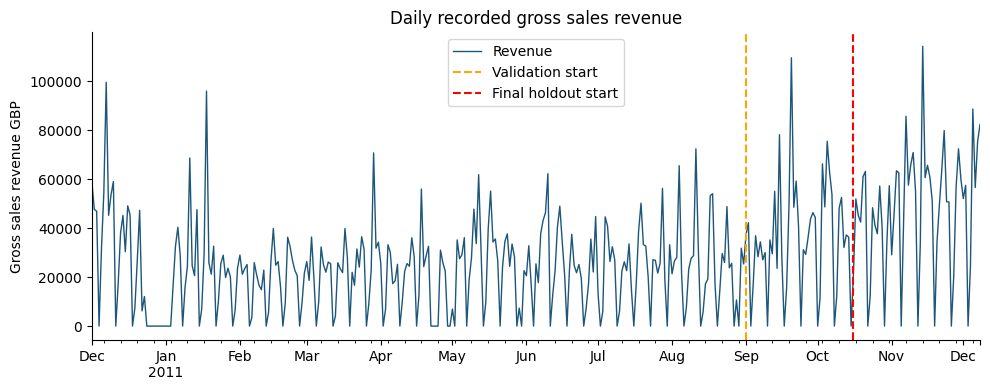

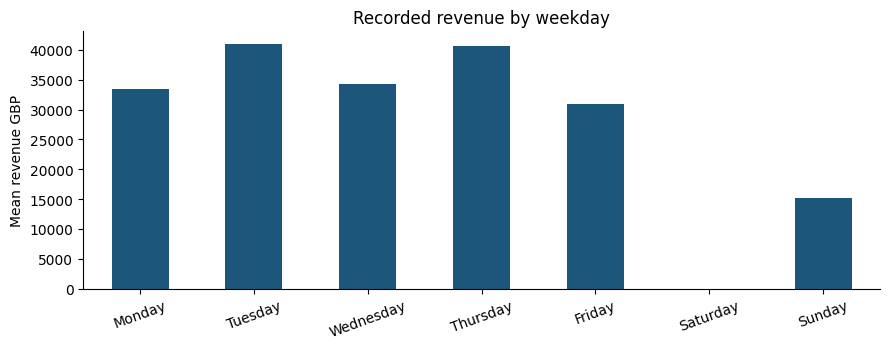

In [ ]:
def aggregate(d):
    idx = pd.date_range('2010-12-01', '2011-12-08', freq='D', name='Date')
    daily = d.groupby('Date').agg(Revenue=('Revenue','sum'), Units=('Quantity','sum'),
                                Invoices=('InvoiceNo','nunique'), Lines=('InvoiceNo','size'))
    return daily.reindex(idx, fill_value=0)
daily = aggregate(clean)
y = daily['Revenue']
display(y.describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame())
print({'calendar_days':len(y), 'positive_days':int((y>0).sum()), 'zero_days':int((y==0).sum()),
       'total_revenue':y.sum(), 'invoices':clean.InvoiceNo.nunique(), 'countries':clean.Country.nunique()})
dow = daily.assign(Weekday=daily.index.day_name()).groupby('Weekday')['Revenue'].agg(['count','mean','median','sum'])
display(dow.reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']))
monthly = y.resample('MS').agg(['sum','mean','count'])
display(monthly)
fig, ax = plt.subplots()
y.plot(ax=ax, color='#1c567b', lw=1)
ax.axvline(pd.Timestamp('2011-09-01'), color='orange', ls='--', label='Validation start')
ax.axvline(pd.Timestamp('2011-10-16'), color='red', ls='--', label='Final holdout start')
ax.set(ylabel='Gross sales revenue GBP', xlabel='', title='Daily recorded gross sales revenue')
ax.legend();fig.tight_layout();fig.savefig(RESULTS/'figure_4_1_daily.png', dpi=180);plt.show()
fig, ax = plt.subplots(figsize=(9,3.6))
dow.reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])['mean'].plot.bar(ax=ax,color='#1c567b',rot=20)
ax.set(ylabel='Mean revenue GBP',xlabel='',title='Recorded revenue by weekday')
fig.tight_layout();fig.savefig(RESULTS/'figure_4_2_weekday.png',dpi=180);plt.show()

In [ ]:
def make_features(series):
    X = pd.DataFrame(index=series.index)
    for lag in [1,2,3,7,14,21,28]:
        X[f'lag_{lag}'] = series.shift(lag)
    for window in [7,14,28]:
        X[f'mean_{window}'] = series.shift(1).rolling(window).mean()
        X[f'std_{window}'] = series.shift(1).rolling(window).std()
    X['weekday_mean_4'] = pd.concat([series.shift(k) for k in [7,14,21,28]],axis=1).mean(axis=1)
    X['trend'] = np.arange(len(series))
    X['day_of_month'] = series.index.day
    X['month_sin'] = np.sin(2*np.pi*series.index.month/12)
    X['month_cos'] = np.cos(2*np.pi*series.index.month/12)
    for day in range(1,7):
        X[f'dow_{day}'] = (series.index.dayofweek==day).astype(int)
    return X.dropna()
X = make_features(y)
train = X.index[X.index < '2011-09-01']
valid = X.index[(X.index >= '2011-09-01') & (X.index < '2011-10-16')]
test = X.index[X.index >= '2011-10-16']
dev = X.index[X.index < '2011-10-16']
splits = pd.DataFrame([{'Partition':n,'Start':i.min().date(),'End':i.max().date(),'Days':len(i)} for n,i in [('Training',train),('Validation',valid),('Final holdout',test)]])
display(splits)
# Invariance to future perturbations checks feature timing.
cut = pd.Timestamp('2011-10-16')
altered = y.copy(); altered.loc[altered.index>=cut] += 1_000_000
pd.testing.assert_frame_equal(make_features(y).loc[:cut],make_features(altered).loc[:cut])
assert train.max()<valid.min() and valid.max()<test.min()
print('Feature timing and partition assertions passed;', X.shape[1], 'predictors')

,Partition,Start,End,Days
0,Training,2010-12-29,2011-08-31,246
1,Validation,2011-09-01,2011-10-15,45
2,Final holdout,2011-10-16,2011-12-08,54


Feature timing and partition assertions passed; 24 predictors


In [ ]:
specs = {
    'Linear regression': (make_pipeline(StandardScaler(), LinearRegression()), {}),
    'Ridge': (make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha':[0.1,1,10,100,1000]}),
    'Random Forest': (RandomForestRegressor(n_estimators=250, random_state=SEED, n_jobs=2),
                      {'max_depth':[3,6,None], 'min_samples_leaf':[3,10]}),
    'Gradient boosting': (HistGradientBoostingRegressor(random_state=SEED, early_stopping=False),
                          {'max_iter':[100,200], 'learning_rate':[.03,.1], 'max_leaf_nodes':[7,15], 'l2_regularization':[1,10]})
}
cv = TimeSeriesSplit(n_splits=3, test_size=28)
fit_valid, best_params, tuning_rows = {}, {}, []
for name,(estimator,grid) in specs.items():
    search = GridSearchCV(estimator, grid, cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
    search.fit(X.loc[train], y.loc[train])
    fit_valid[name] = search.best_estimator_
    best_params[name] = search.best_params_
    tuning_rows.append({'Model':name,'CV_MAE':-search.best_score_,'Parameters':str(search.best_params_)})
tuning = pd.DataFrame(tuning_rows)
display(tuning)

,Model,CV_MAE,Parameters
0,Linear regression,11387.059191,{}
1,Ridge,9017.534903,{'ridge__alpha': 100}
2,Random Forest,8554.445320,"{'max_depth': None, 'min_samples_leaf': 10}"
3,Gradient boosting,8382.116699,"{'l2_regularization': 10, 'learning_rate': 0.0..."


In [ ]:
def baseline_predictions(series, idx, history_end):
    p = pd.DataFrame(index=idx)
    p['Historical mean'] = series.loc[:history_end].mean()
    p['Naive'] = series.shift(1).loc[idx]
    p['Seasonal naive'] = series.shift(7).loc[idx]
    p['Moving average 7'] = series.shift(1).rolling(7).mean().loc[idx]
    p['Weekday mean 4'] = pd.concat([series.shift(k) for k in [7,14,21,28]],axis=1).mean(axis=1).loc[idx]
    return p

def scores(actual, prediction, scale_history):
    scale = scale_history.diff(7).abs().dropna().mean()
    error = prediction - actual
    positive = actual > 0
    return {'MAE':mean_absolute_error(actual,prediction),
            'RMSE':float(np.sqrt(mean_squared_error(actual,prediction))),
            'WAPE_percent':100*float(np.abs(error).sum()/actual.abs().sum()),
            'MASE_7':float(np.abs(error).mean()/scale),
            'Bias_GBP':float(error.mean()),
            'MAPE_positive_percent':100*float((error[positive].abs()/actual[positive]).mean())}

def evaluate(predictions, actual, scale_history):
    return pd.DataFrame({name:scores(actual,predictions[name],scale_history) for name in predictions}).T.sort_values('MAE')
vp = baseline_predictions(y,valid,train.max())
for name,model in fit_valid.items():
    vp[name] = np.clip(model.predict(X.loc[valid]),0,None)
validation_scores = evaluate(vp,y.loc[valid],y.loc[:train.max()])
champion = validation_scores.loc[list(specs)].MAE.idxmin()
base_names = ['Historical mean','Naive','Seasonal naive','Moving average 7','Weekday mean 4']
reference = validation_scores.loc[base_names].MAE.idxmin()
display(validation_scores.round(3))
print({'validation_selected_model':champion,'validation_selected_baseline':reference})
final_models = {}
tp = baseline_predictions(y,test,dev.max())
for name, model in fit_valid.items():
    fitted = clone(model).fit(X.loc[dev],y.loc[dev])
    final_models[name] = fitted
    tp[name] = np.clip(fitted.predict(X.loc[test]),0,None)
holdout_scores = evaluate(tp,y.loc[test],y.loc[:dev.max()])
holdout_scores['MAE_improvement_percent'] = 100*(1-holdout_scores.MAE/holdout_scores.loc[reference,'MAE'])
display(holdout_scores.round(3))

,MAE,RMSE,WAPE_percent,MASE_7,Bias_GBP,MAPE_positive_percent
Random Forest,12101.282,18654.942,34.178,1.203,-10037.408,29.893
Weekday mean 4,13332.684,19241.830,37.655,1.325,-5555.238,38.341
Gradient boosting,14193.039,20645.149,40.085,1.411,-11990.014,33.683
Ridge,14853.234,21118.965,41.950,1.476,-11986.594,36.103
Seasonal naive,16476.086,22900.562,46.533,1.638,-2250.377,50.335
Linear regression,17450.127,23567.483,49.284,1.734,-14445.420,46.181
Moving average 7,18337.259,24034.180,51.790,1.823,-990.645,42.438
Historical mean,21158.374,26368.031,59.757,2.103,-12440.867,45.444
Naive,22668.435,28796.139,64.022,2.253,563.716,51.419


{'validation_selected_model': 'Random Forest', 'validation_selected_baseline': 'Weekday mean 4'}


,MAE,RMSE,WAPE_percent,MASE_7,Bias_GBP,MAPE_positive_percent,MAE_improvement_percent
Weekday mean 4,11137.597,15169.911,23.538,1.014,-4223.971,24.781,0.000
Seasonal naive,11344.658,16345.841,23.976,1.033,-3079.231,25.980,-1.859
Random Forest,11545.840,16708.275,24.401,1.051,-6551.916,27.603,-3.665
Gradient boosting,13169.720,17691.851,27.833,1.199,-8322.031,29.067,-18.246
Ridge,13689.044,17892.678,28.930,1.246,-8735.126,24.979,-22.908
Linear regression,13892.776,18402.769,29.361,1.265,-7706.488,24.829,-24.738
Moving average 7,19867.082,25343.164,41.987,1.808,-2640.979,33.442,-78.379
Naive,25233.333,31817.834,53.328,2.297,-1525.399,43.775,-126.560
Historical mean,29753.556,34024.291,62.881,2.708,-22596.064,52.016,-167.145


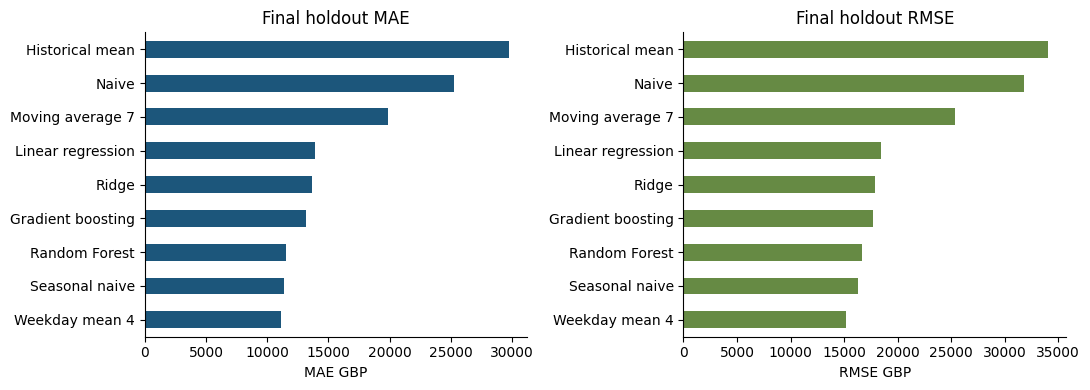

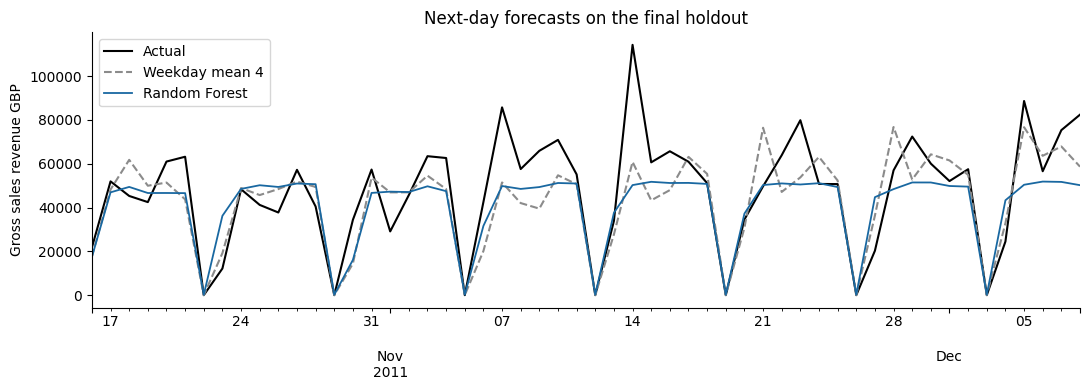

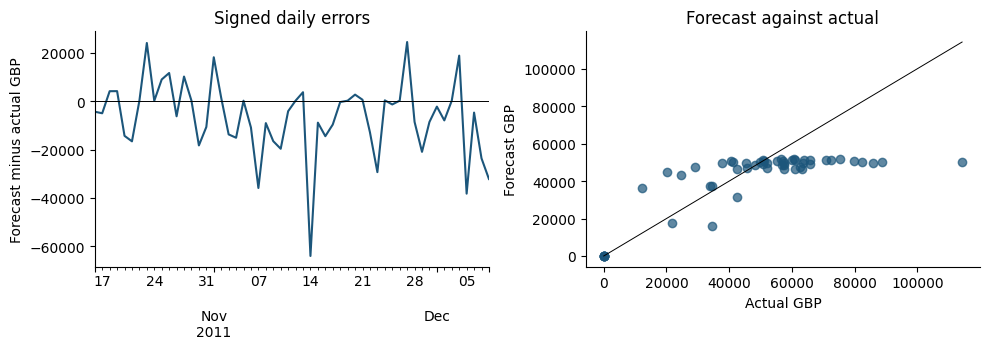

In [ ]:
fig,axs = plt.subplots(1,2,figsize=(11,4))
holdout_scores.MAE.sort_values().plot.barh(ax=axs[0],color='#1c567b')
axs[0].set(xlabel='MAE GBP',ylabel='',title='Final holdout MAE')
holdout_scores.RMSE.sort_values().plot.barh(ax=axs[1],color='#668a44')
axs[1].set(xlabel='RMSE GBP',ylabel='',title='Final holdout RMSE')
fig.tight_layout();fig.savefig(RESULTS/'figure_4_3_metrics.png',dpi=180);plt.show()
fig,ax = plt.subplots(figsize=(11,4))
y.loc[test].plot(ax=ax,color='black',lw=1.5,label='Actual')
tp[reference].plot(ax=ax,color='#8b8b8b',ls='--',label=reference)
tp[champion].plot(ax=ax,color='#1968a1',lw=1.3,label=champion)
ax.set(ylabel='Gross sales revenue GBP',xlabel='',title='Next-day forecasts on the final holdout')
ax.legend();fig.tight_layout();fig.savefig(RESULTS/'figure_4_4_predictions.png',dpi=180);plt.show()
errors = tp[champion] - y.loc[test]
fig,axs = plt.subplots(1,2,figsize=(10,3.6))
errors.plot(ax=axs[0],color='#1c567b');axs[0].axhline(0,color='black',lw=.7)
axs[0].set(ylabel='Forecast minus actual GBP',xlabel='',title='Signed daily errors')
axs[1].scatter(y.loc[test],tp[champion],color='#1c567b',alpha=.7)
lim=max(y.loc[test].max(),tp[champion].max());axs[1].plot([0,lim],[0,lim],color='black',lw=.7)
axs[1].set(xlabel='Actual GBP',ylabel='Forecast GBP',title='Forecast against actual')
fig.tight_layout();fig.savefig(RESULTS/'figure_4_5_errors.png',dpi=180);plt.show()

{'comparison': 'Weekday mean 4 minus Random Forest', 'mean_absolute_error_gain_GBP': -408.24366068126864, 'CI95_low': -2924.3394295380076, 'CI95_high': 2026.9206667835326, 'block_days': 7, 'replications': 5000, 'days_champion_better': 21, 'tied_days': 0}


,Block,Start,End,Model,MAE,RMSE,WAPE_percent,MASE_7,Bias_GBP,MAPE_positive_percent
0,1,2011-10-16,2011-11-02,Weekday mean 4,7809.061,10143.112,20.396,0.711,491.636,24.038
1,1,2011-10-16,2011-11-02,Random Forest,8818.329,11247.513,23.032,0.803,427.682,32.655
2,2,2011-11-03,2011-11-20,Weekday mean 4,13728.526,19317.467,26.727,1.250,-13015.508,24.707
3,2,2011-11-03,2011-11-20,Random Forest,12750.295,19839.354,24.822,1.161,-11971.266,21.173
4,3,2011-11-21,2011-12-08,Weekday mean 4,11875.203,14640.061,22.706,1.081,-148.042,25.594
5,3,2011-11-21,2011-12-08,Random Forest,13068.897,17815.523,24.989,1.190,-8112.163,28.580


,MAE,RMSE,WAPE_percent,MASE_7,Bias_GBP,MAPE_positive_percent
Weekday mean 4,12796.388,16260.391,23.538,1.165,-4853.073,24.781
Seasonal naive,13034.288,17520.852,23.976,1.186,-3537.840,25.980
Random Forest,13235.424,17909.171,24.346,1.205,-7557.742,27.603
Linear regression,13820.861,18847.639,25.423,1.258,-10995.315,24.829
Ridge,14137.582,18705.055,26.005,1.287,-11626.357,24.979
Gradient boosting,14503.592,18893.562,26.678,1.320,-10189.057,29.067
Moving average 7,16054.610,20563.460,29.531,1.461,-9805.715,33.442
Naive,20893.013,26736.850,38.431,1.902,-9851.062,43.775
Historical mean,30503.050,35200.112,56.108,2.776,-29643.322,52.016


,Actual,Forecast,Error,Absolute_error
Date,,,,
2011-11-14,114237.40,50235.15,-64002.25,64002.25
2011-12-05,88620.84,50385.83,-38235.01,38235.01
2011-11-07,85705.30,49812.09,-35893.21,35893.21
2011-12-08,82371.55,50199.25,-32172.30,32172.30
2011-11-23,79847.00,50507.67,-29339.33,29339.33


,Feature,Increase_MAE,SD
3,lag_7,4275.21,776.79
13,weekday_mean_4,2651.38,487.66
0,lag_1,538.87,233.90
6,lag_28,476.21,243.81
22,dow_5,412.94,48.34
5,lag_21,388.73,93.92
4,lag_14,109.08,133.16
2,lag_3,46.38,46.11
1,lag_2,44.34,18.12
23,dow_6,35.73,16.97


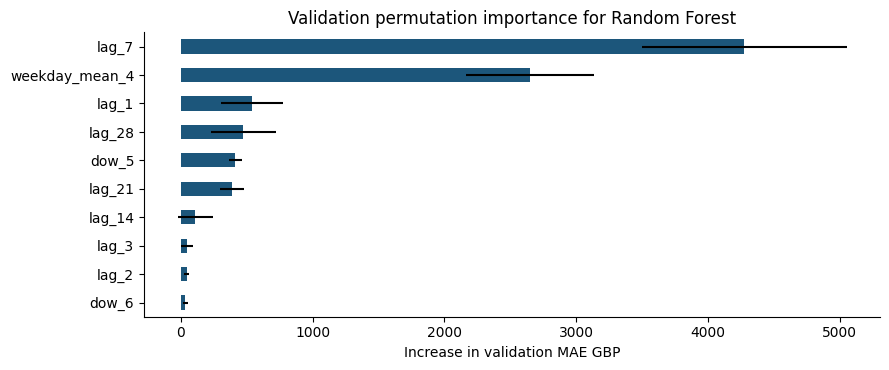

In [ ]:
gain = (tp[reference]-y.loc[test]).abs()-(tp[champion]-y.loc[test]).abs()
rng = np.random.default_rng(SEED)
n = len(gain); block = 7; repetitions = 5000
boot = np.empty(repetitions)
for b in range(repetitions):
    starts = rng.integers(0,n,size=int(np.ceil(n/block)))
    ids = np.concatenate([(s+np.arange(block))%n for s in starts])[:n]
    boot[b] = gain.to_numpy()[ids].mean()
bootstrap = {'comparison':f'{reference} minus {champion}', 'mean_absolute_error_gain_GBP':float(gain.mean()),
             'CI95_low':float(np.quantile(boot,.025)), 'CI95_high':float(np.quantile(boot,.975)),
             'block_days':block,'replications':repetitions,
             'days_champion_better':int((gain>0).sum()),'tied_days':int((gain==0).sum())}
print(bootstrap)
blocks=[]
for i,idx in enumerate(np.array_split(test,3),1):
    for name in [reference,champion]:
        r=scores(y.loc[idx],tp.loc[idx,name],y.loc[:dev.max()])
        blocks.append({'Block':i,'Start':str(idx.min().date()),'End':str(idx.max().date()),'Model':name,**r})
block_scores=pd.DataFrame(blocks);display(block_scores.round(3))
active = y.loc[test]>0
active_scores=evaluate(tp.loc[active],y.loc[test][active],y.loc[:dev.max()])
display(active_scores.round(3))
worst = pd.DataFrame({'Actual':y.loc[test],'Forecast':tp[champion],'Error':errors,'Absolute_error':errors.abs()}).nlargest(5,'Absolute_error')
display(worst.round(2))
perm=permutation_importance(fit_valid[champion],X.loc[valid],y.loc[valid],scoring='neg_mean_absolute_error',n_repeats=30,random_state=SEED)
importance=pd.DataFrame({'Feature':X.columns,'Increase_MAE':perm.importances_mean,'SD':perm.importances_std}).sort_values('Increase_MAE',ascending=False)
display(importance.head(10).round(2))
fig,ax=plt.subplots(figsize=(9,3.8))
importance.head(10).iloc[::-1].plot.barh(x='Feature',y='Increase_MAE',xerr='SD',ax=ax,color='#1c567b',legend=False)
ax.set(xlabel='Increase in validation MAE GBP',ylabel='',title=f'Validation permutation importance for {champion}')
fig.tight_layout();fig.savefig(RESULTS/'figure_4_6_importance.png',dpi=180);plt.show()

In [ ]:
clean_keep, audit_keep = clean_transactions(raw,drop_duplicates=False)
y_keep = aggregate(clean_keep)['Revenue']
X_keep = make_features(y_keep)
p_keep = baseline_predictions(y_keep,test,dev.max())
for name,model in fit_valid.items():
    fitted=clone(model).fit(X_keep.loc[dev],y_keep.loc[dev])
    p_keep[name]=np.clip(fitted.predict(X_keep.loc[test]),0,None)
duplicate_scores=evaluate(p_keep,y_keep.loc[test],y_keep.loc[:dev.max()])
display(duplicate_scores.round(3))
summary = {'provenance':provenance,'rows_clean':len(clean),'missing_customer_retained':int(clean.CustomerID.isna().sum()),
 'total_revenue':float(y.sum()),'calendar_days':len(y),'zero_days':int((y==0).sum()),'positive_days':int((y>0).sum()),
 'invoices':int(clean.InvoiceNo.nunique()),'countries':int(clean.Country.nunique()),'predictors':X.shape[1],
 'selected_model':champion,'selected_baseline':reference,'bootstrap':bootstrap,'best_params':best_params,
 'daily_descriptive':y.describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_dict(),
 'holdout_revenue':float(y.loc[test].sum()),'holdout_zero_days':int((y.loc[test]==0).sum()),
 'holdout_mean':float(y.loc[test].mean()),'holdout_peak':float(y.loc[test].max()),
 'holdout_top5_error_share':float(errors.abs().nlargest(5).sum()/errors.abs().sum()),
 'positive_top10_revenue_share':float(y.nlargest(10).sum()/y.sum()),
 'train_mean':float(y.loc[:train.max()].mean()),'valid_mean':float(y.loc[valid].mean()),
 'scale_development':float(y.loc[:dev.max()].diff(7).abs().dropna().mean()),
 'duplicate_retention_total':float(y_keep.sum())}
for name,table in {'cleaning_audit':audit,'splits':splits,'validation_metrics':validation_scores,'holdout_metrics':holdout_scores,
 'tuning':tuning,'weekday':dow,'monthly':monthly,'block_metrics':block_scores,'active_day_metrics':active_scores,
 'worst_errors':worst,'importance':importance,'duplicate_sensitivity':duplicate_scores,
 'daily_series':daily,'holdout_predictions':tp.assign(Actual=y.loc[test])}.items():
    table.to_csv(RESULTS/f'{name}.csv',index=True)
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2,default=str))
(RESULTS/'data_provenance.json').write_text(json.dumps(provenance,indent=2))
print('Results and figures saved in', RESULTS)

,MAE,RMSE,WAPE_percent,MASE_7,Bias_GBP,MAPE_positive_percent
Weekday mean 4,11150.018,15188.426,23.483,1.014,-4244.557,24.698
Seasonal naive,11361.082,16367.611,23.928,1.033,-3081.208,25.907
Random Forest,11502.715,16680.133,24.226,1.046,-6628.441,27.172
Gradient boosting,13403.192,17856.853,28.229,1.218,-8821.041,29.068
Ridge,13729.529,17931.974,28.916,1.248,-8773.661,24.940
Linear regression,13947.287,18454.255,29.375,1.268,-7764.917,24.823
Moving average 7,19887.715,25379.191,41.886,1.808,-2644.145,33.187
Naive,25284.443,31884.020,53.252,2.298,-1527.685,43.676
Historical mean,29854.406,34126.043,62.877,2.714,-22710.208,51.975


Results and figures saved in /content/results
